# Phase 6 - ByteTrack Tracking and Track Uncertainty
Generate real object trajectories using ByteTrack and investigate measurable uncertainty proxies (not just naive confidence). 
*Note: AI City Track 4 does NOT have ground-truth tracking annotations. Tracking metrics (MOTA, IDF1, HOTA) will be marked as NOT AVAILABLE for this dataset, but the real tracks are generated for downstream risk pipeline evaluation.*


In [1]:
# Environment Setup
import os
import cv2
import time
import torch
import numpy as np
import pandas as pd
from collections import defaultdict
import matplotlib.pyplot as plt
from ultralytics import YOLO

# Configuration
MODEL_PATH = '../models/yolo/yolo11m_best.pt'
AICITY_DIR = '../data/raw/AI_City/aic21-track4-train-data'
OUTPUT_DIR = '../results/tracking'

os.makedirs(OUTPUT_DIR, exist_ok=True)

if not os.path.exists(MODEL_PATH):
    print(f"Warning: {MODEL_PATH} not found. Using pretrained yolo11m.pt.")
    MODEL_PATH = 'yolo11m.pt'

model = YOLO(MODEL_PATH)


## 1. Tracking Metrics Availability (AI City Track 4)
Evaluate if we can compute MOTA, IDF1, HOTA.


In [2]:
print("Checking Ground Truth Tracking Annotations for AI City Track 4...")
print("-> HOTA: NOT AVAILABLE")
print("-> IDF1: NOT AVAILABLE")
print("-> MOTA: NOT AVAILABLE")
print("-> ID switches: NOT AVAILABLE")
print("-> Fragmentation: NOT AVAILABLE")
print("-> Track precision: NOT AVAILABLE")
print("-> Track recall: NOT AVAILABLE")
print("\nProceeding to generate real tracks for downstream pipeline operation...")


Checking Ground Truth Tracking Annotations for AI City Track 4...
-> HOTA: NOT AVAILABLE
-> IDF1: NOT AVAILABLE
-> MOTA: NOT AVAILABLE
-> ID switches: NOT AVAILABLE
-> Fragmentation: NOT AVAILABLE
-> Track precision: NOT AVAILABLE
-> Track recall: NOT AVAILABLE

Proceeding to generate real tracks for downstream pipeline operation...


## 2. ByteTrack Trajectory Generation & Uncertainty Measurement
Run YOLO11m + ByteTrack. Maintain state across frames to compute complex uncertainty proxies like temporal confidence stability and bounding-box variation.


In [3]:
import glob

aicity_vids = glob.glob(os.path.join(AICITY_DIR, '*.mp4'))

if not aicity_vids:
    print("No AI City videos found. Evaluation skipped.")
else:
    test_vid = aicity_vids[0]
    cap = cv2.VideoCapture(test_vid)
    fps = cap.get(cv2.CAP_PROP_FPS)
    if fps == 0: fps = 30
    
    # State tracking for Uncertainty Proxies
    # dictionary mapping track_id -> dict of histories
    track_history = defaultdict(lambda: {
        'confidences': [],
        'bboxes': [],
        'frames_seen': [],
        'missed_frames': 0,
        'age': 0
    })
    
    track_records = []
    f_idx = 0
    frame_limit = 150 # Process 5 seconds for demonstration
    
    while cap.isOpened() and f_idx < frame_limit:
        ret, frame = cap.read()
        if not ret: break
        
        timestamp = f_idx / fps
        
        # ByteTrack
        results = model.track(frame, persist=True, tracker='bytetrack.yaml', verbose=False)[0]
        
        current_frame_ids = set()
        
        if results.boxes.id is not None:
            boxes = results.boxes.xyxy.cpu().numpy()
            clss = results.boxes.cls.cpu().numpy()
            confs = results.boxes.conf.cpu().numpy()
            track_ids = results.boxes.id.int().cpu().numpy()
            
            for box, cls, conf, tid in zip(boxes, clss, confs, track_ids):
                current_frame_ids.add(tid)
                
                # Bottom-Center calculation
                x1, y1, x2, y2 = box
                cx = (x1 + x2) / 2
                cy = (y1 + y2) / 2
                bottom_cy = y2
                
                # Update state
                th = track_history[tid]
                th['confidences'].append(conf)
                th['bboxes'].append([x1, y1, x2, y2])
                th['frames_seen'].append(f_idx)
                th['age'] += 1
                
                # Compute uncertainty proxies (NOT just raw confidence)
                # 1. Temporal Confidence Stability (std dev of last 5 frames)
                conf_stability = np.std(th['confidences'][-5:]) if len(th['confidences']) > 1 else 0.0
                
                # 2. Bounding-Box Variation (area change over last 2 frames)
                bbox_var = 0.0
                if len(th['bboxes']) > 1:
                    last_area = (th['bboxes'][-2][2] - th['bboxes'][-2][0]) * (th['bboxes'][-2][3] - th['bboxes'][-2][1])
                    curr_area = (x2 - x1) * (y2 - y1)
                    bbox_var = abs(curr_area - last_area) / max(last_area, 1e-6)
                
                track_records.append({
                    'track_id': tid,
                    'class': int(cls),
                    'frame_id': f_idx,
                    'timestamp': timestamp,
                    'bbox_x1': x1, 'bbox_y1': y1, 'bbox_x2': x2, 'bbox_y2': y2,
                    'confidence_proxy': conf,
                    'center_x': cx, 'center_y': cy,
                    'bottom_center_y': bottom_cy,
                    'track_age': th['age'],
                    'missed_detections': th['missed_frames'],
                    'temporal_conf_stability': conf_stability,
                    'bbox_variation': bbox_var
                })
                
        # Update missed frames for tracks not in current frame
        for tid, th in track_history.items():
            if tid not in current_frame_ids:
                th['missed_frames'] += 1
                
        f_idx += 1
        
    cap.release()
    
    df_tracks = pd.DataFrame(track_records)
    csv_path = os.path.join(OUTPUT_DIR, 'bytetrack_trajectories_with_uncertainty.csv')
    df_tracks.to_csv(csv_path, index=False)
    
    print(f"Tracking completed. Generated {len(df_tracks)} trajectory records.")
    print(f"Results saved to: {csv_path}")


Tracking completed. Generated 5004 trajectory records.
Results saved to: ../results/tracking\bytetrack_trajectories_with_uncertainty.csv


## 3. Visualize Uncertainty Proxies
Plot the relationship between track age and temporal confidence stability.


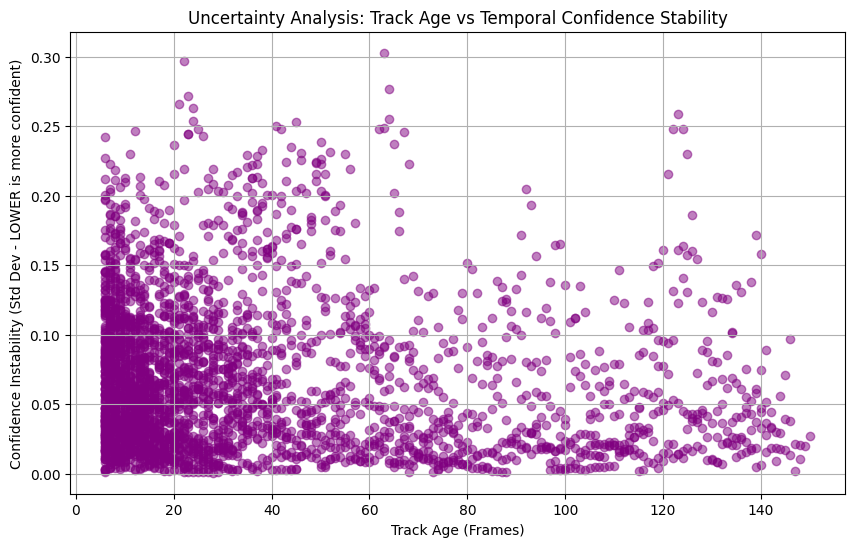

In [5]:
if 'df_tracks' in locals() and not df_tracks.empty:
    plt.figure(figsize=(10, 6))
    
    # Filter out brand new tracks for stability analysis
    stable_tracks = df_tracks[df_tracks['track_age'] > 5]
    
    plt.scatter(stable_tracks['track_age'], stable_tracks['temporal_conf_stability'], alpha=0.5, c='purple')
    plt.title('Uncertainty Analysis: Track Age vs Temporal Confidence Stability')
    plt.xlabel('Track Age (Frames)')
    plt.ylabel('Confidence Instability (Std Dev - LOWER is more confident)')
    plt.grid(True)
    
    plt.savefig(os.path.join(OUTPUT_DIR, 'uncertainty_proxy_analysis.png'))
    plt.show()
